In [1]:
!pip install -q fastai fastbook

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 719.8/719.8 kB 16.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 78.2 MB/s eta 0:00:00


In [3]:
from fastai.vision.all import *
path = untar_data(URLs.PETS)/'images'
def is_cat(x): return x[0].isupper()
dls = ImageDataLoaders.from_name_func(
    path, get_image_files(path), valid_pct=0.2, seed=42,
    label_func=is_cat, item_tfms=Resize(224))

learn = vision_learner(dls, resnet34, metrics=error_rate)
learn.fine_tune(1)

<div><progress max="811706944" value="811712512"></progress> 100.00% [811712512/811706944 00:11&lt;00:00]</div>

Downloading: "https://download.pytorch.org/models/resnet34-b627a593.pth" to /root/.cache/torch/hub/checkpoints/resnet34-b627a593.pth


100%|██████████| 83.3M/83.3M [00:00<00:00, 198MB/s]


epoch,train_loss,valid_loss,error_rate,time
0,0.158477,0.030669,0.011502,23:08


epoch,train_loss,valid_loss,error_rate,time
0,0.060457,0.027978,0.010149,35:40


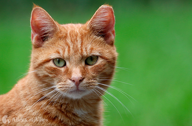

In [5]:
img = PILImage.create('cat_photo.jpg')
img.to_thumb(192)

In [6]:
label, _, probs = learn.predict(img)

print("Prediction:", "Cat" if label == 'True' else "Dog")
print("Probabilities:", probs)

Prediction: Cat
Probabilities: tensor([2.6075e-17, 1.0000e+00])


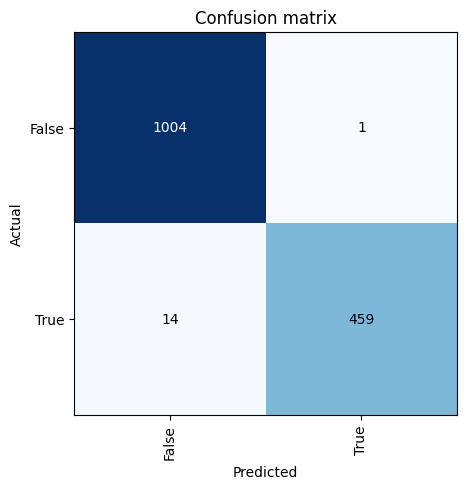

In [8]:
interp = ClassificationInterpretation.from_learner(learn)
interp.plot_confusion_matrix()

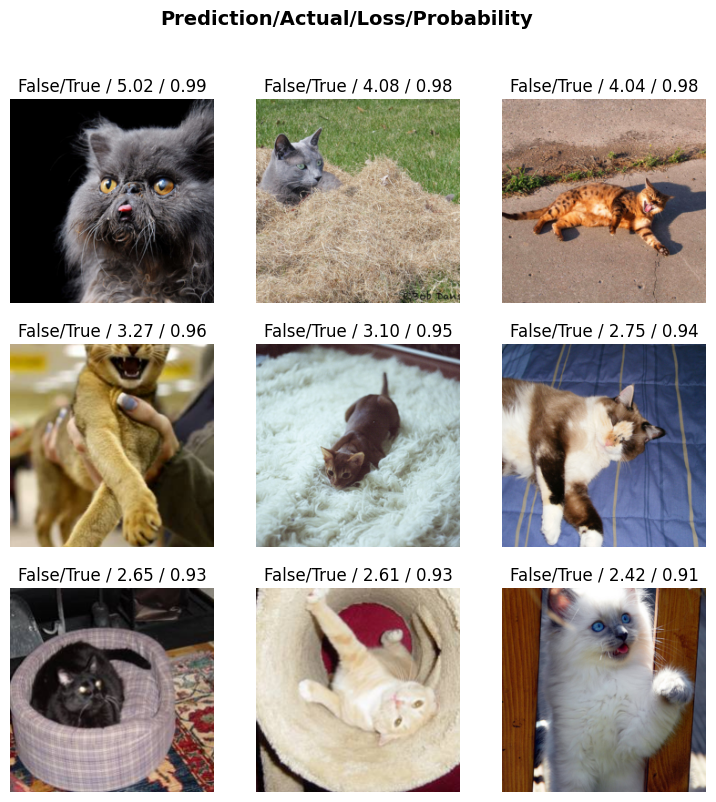

In [9]:
interp.plot_top_losses(9, nrows=3)

this shows the 9 images with the highest loss.